# U-Net++ foreground and classwise ECE 

**Fix:** Defines the missing `normalized()` helper used to identify U-Net++ checkpoint files. All five Seed 42 checkpoints and the frozen patient split are still required.


In [1]:
from __future__ import annotations
import os,re,gc,io,json,math,random,warnings,hashlib,zipfile,shutil
from pathlib import Path
from functools import lru_cache
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage
import torch
import torch.nn as nn
import torch.nn.functional as F

MODEL_KEY = 'UNetPP'
INPUT_ROOT=Path('/kaggle/input')
OUTPUT_DIR=Path('/kaggle/working/Review6_ECE_'+MODEL_KEY)
TABLE_DIR=OUTPUT_DIR/'tables'
FIGURE_DIR=OUTPUT_DIR/'figures'
for p in [OUTPUT_DIR,TABLE_DIR,FIGURE_DIR]:p.mkdir(parents=True,exist_ok=True)
DATA_ROOT_OVERRIDE=None          # e.g. '/kaggle/input/ms3seg/MS3SEG'
CHECKPOINT_INPUT_ROOT=None       # e.g. '/kaggle/input/unetpp-five-fold-checkpoints'
INFERENCE_BATCH_SIZE=2          # lower to 1 if GPU RAM is tight
CALIBRATION_BINS=20
EXPECTED_SPLIT_SHA256='d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459'
EXPECTED_TEST_IDS=['006','008','014','024','027','033','036','040','041','042',
                   '046','055','057','071','074','076','079','085','088','100']
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Model:',MODEL_KEY,'device:',DEVICE)
if DEVICE.type!='cuda':warnings.warn('GPU recommended for five-model ensemble inference')

Model: UNetPP device: cuda


In [2]:
# Input discovery: works with nested Kaggle fold folders and split CSV stored separately.
def discover_ms3seg_root():
    if DATA_ROOT_OVERRIDE:
        p=Path(DATA_ROOT_OVERRIDE)
        if not ((p/'MS_100_patient_preprocessed').is_dir() and (p/'MS_100_patient_masks').is_dir()):
            raise FileNotFoundError(f'Invalid MS3SEG root: {p}')
        return p
    hits=[p.parent for p in INPUT_ROOT.rglob('MS_100_patient_preprocessed')
          if (p.parent/'MS_100_patient_masks').is_dir()]
    hits=list(dict.fromkeys(hits))
    if len(hits)!=1:
        raise FileNotFoundError(f'Found {len(hits)} MS3SEG roots: {hits}. Set DATA_ROOT_OVERRIDE in cell 1.')
    return hits[0]

def fold_of(path):
    # Prefer the nearest folder named FOLD0..FOLD4, not the parent Kaggle
    # dataset name (which may contain all five fold numbers).
    parts=re.split(r'[\\/]+',str(path))
    for part in reversed(parts):
        m=re.search(r'(?:^|[_\-])fold[_\-\s]*([0-4])(?:$|[_\-\s.])',part.lower())
        if m:return int(m.group(1))
    return None

def is_weight_file(path):
    name=Path(path).name.lower()
    return (name.endswith(('.pt','.pth','.ckpt')) and
            any(k in name for k in ('best','model','checkpoint','weight')))

def normalized(value):
    # Normalize Kaggle dataset names and checkpoint paths for robust matching.
    return re.sub(r'[^a-z0-9]+', '', str(value).lower())

def inventory_checkpoint_candidates():
    root=Path(CHECKPOINT_INPUT_ROOT) if CHECKPOINT_INPUT_ROOT else INPUT_ROOT
    if not root.is_dir(): raise FileNotFoundError(f'CHECKPOINT_INPUT_ROOT does not exist: {root}')
    files=[]; zips=[]; splits=[]
    for p in root.rglob('*'):
        if not p.is_file():continue
        if is_weight_file(p):files.append(('file',p,None))
        elif p.name=='patient_level_5fold_split.csv':splits.append(('file',p,None))
        elif p.suffix.lower()=='.zip':
            try:
                with zipfile.ZipFile(p) as z:
                    names=[i.filename for i in z.infolist() if not i.is_dir()]
                for name in names:
                    if is_weight_file(name):files.append(('zip',p,name))
                    elif Path(name).name=='patient_level_5fold_split.csv':splits.append(('zip',p,name))
                zips.append(p)
            except (zipfile.BadZipFile,OSError) as exc:
                print('Skipping unreadable zip:',p,exc)
    if CHECKPOINT_INPUT_ROOT is None:
        tags=('unetpp','unetplusplus','anato')
        files=[c for c in files if any(tag in normalized(str(c[1])) for tag in tags)]
        # Split may be supplied separately, so do not filter splits.
    print('Checkpoint candidates:',len(files),'| split CSV candidates:',len(splits),'| ZIPs scanned:',len(zips))
    for typ,p,member in files[:40]:print('  WEIGHT',typ,p,member or '')
    for typ,p,member in splits[:15]:print('  SPLIT ',typ,p,member or '')
    return files,splits

def read_candidate(candidate):
    typ,p,member=candidate
    if typ=='file':return p.read_bytes()
    with zipfile.ZipFile(p) as z:return z.read(member)

def discover_all_fold_bundles():
    weights,splits=inventory_checkpoint_candidates()
    # Locate the exact original patient split by SHA256; do not guess or replace it.
    valid_splits=[]
    for candidate in splits:
        if hashlib.sha256(read_candidate(candidate)).hexdigest()==EXPECTED_SPLIT_SHA256:
            valid_splits.append(candidate)
    if not valid_splits:
        raise FileNotFoundError('No split CSV matching the frozen split SHA256. Attach the original patient_level_5fold_split.csv along with the trained model checkpoints.')
    split_bytes=read_candidate(valid_splits[0])
    grouped={i:[] for i in range(5)}
    for cand in weights:
        typ,p,member=cand
        fold=fold_of(str(p)+'/'+(member or ''))
        if fold is not None:grouped[fold].append(cand)
    # Each original training fold can export multiple checkpoints. For the standard
    # locked-test ensemble, use the exact best_model.pt from each fold.
    # Do not accidentally select best_nwmh_model, best_weighted_model,
    # or last_checkpoint; these are different checkpoint-selection rules.
    selected = {}
    for fold, items in grouped.items():
        best = [candidate for candidate in items
                if Path(candidate[2] or candidate[1]).name.lower() == 'best_model.pt']
        print(f'Fold {fold}: {len(items)} total weights, {len(best)} best_model.pt candidate(s)')
        if len(best) != 1:
            print('Candidates:', [(str(p), member) for _, p, member in items])
            raise RuntimeError(f'Expected exactly one best_model.pt for Fold {fold}; found {len(best)}. Set CHECKPOINT_INPUT_ROOT to the correct Kaggle dataset.')
        selected[fold] = best[0]
    out=Path('/kaggle/working')/'review6_resolved_unetpp'
    out.mkdir(parents=True,exist_ok=True)
    result={}
    for fold in range(5):
        cand=selected[fold]
        cp=out/f'fold{fold}_best_model.pt'
        if cand[0]=='file':
            cp=cand[1] # avoid unnecessary copying of large weights
        else:
            with zipfile.ZipFile(cand[1]) as z, z.open(cand[2]) as src, open(cp,'wb') as dst:
                shutil.copyfileobj(src,dst)
        split=out/f'fold{fold}_patient_level_5fold_split.csv'
        split.write_bytes(split_bytes)
        result[fold]={'checkpoint':cp,'split':split,'source':str(cand[1])+(('::'+cand[2]) if cand[2] else '')}
        print('Fold',fold,'checkpoint:',result[fold]['source'])
    return result

DATA_ROOT=discover_ms3seg_root()
PREPROCESSED_DIR=DATA_ROOT/'MS_100_patient_preprocessed'
MASKS_DIR=DATA_ROOT/'MS_100_patient_masks'
print('MS3SEG root:',DATA_ROOT)
CHECKPOINT_BUNDLES=discover_all_fold_bundles()


MS3SEG root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
Checkpoint candidates: 20 | split CSV candidates: 5 | ZIPs scanned: 0
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD4_FULL60_TRANSFER/best_weighted_model.pt 
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD4_FULL60_TRANSFER/last_checkpoint.pt 
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD4_FULL60_TRANSFER/best_nwmh_model.pt 
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD4_FULL60_TRANSFER/best_model.pt 
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD0_FULL60_TRANSFER/best_weighted_model.pt 
  WEIGHT file /kaggle/input/datasets/saifsamiul/u-net-5-fold-oof-evaluation/MS3SEG_BASELINE_UNETPP_FOLD0_FULL60_TRANSFER/last_checkpoint.pt 
  WEIGHT file /kaggl

In [3]:
mask_roots = [
    path
    for path in MASKS_DIR.iterdir()
    if path.is_dir()
]


def select_mask_root(kind):
    if kind == "vent":
        matches = [
            path
            for path in mask_roots
            if "vent" in path.name.lower()
        ]

    elif kind == "nwmh":
        matches = [
            path
            for path in mask_roots
            if (
                "nwmh" in path.name.lower()
                or "normal" in path.name.lower()
            )
            and "abwmh" not in path.name.lower()
            and "abnormal" not in path.name.lower()
        ]

    else:
        matches = [
            path
            for path in mask_roots
            if (
                "abwmh" in path.name.lower()
                or "abnormal" in path.name.lower()
            )
        ]

    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one {kind} mask root, found: {matches}"
        )

    return matches[0]


VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")


def find_unique_file(
    folder,
    patterns,
    description,
):
    found = []

    for pattern in patterns:
        found.extend(
            folder.glob(pattern)
        )

    unique = []
    seen = set()

    for path in found:
        if (
            path.is_file()
            and path not in seen
        ):
            unique.append(path)
            seen.add(path)

    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected one file in {folder}; "
            f"found {len(unique)}: {unique}"
        )

    return unique[0]


patient_dirs = sorted(
    path
    for path in PREPROCESSED_DIR.iterdir()
    if (
        path.is_dir()
        and re.fullmatch(
            r"\d{3}",
            path.name,
        )
    )
)

records = []

for patient_dir in patient_dirs:
    patient_id = patient_dir.name

    records.append({
        "patient_id": patient_id,
        "flair": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_FLAIR.nii",
                    f"{patient_id}_FLAIR.nii.gz",
                ],
                f"{patient_id} FLAIR",
            )
        ),
        "t1": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T1WI_reg.nii",
                    f"{patient_id}_T1WI_reg.nii.gz",
                    "*T1*reg*.nii*",
                ],
                f"{patient_id} T1",
            )
        ),
        "t2": str(
            find_unique_file(
                patient_dir,
                [
                    f"{patient_id}_T2WI_reg.nii",
                    f"{patient_id}_T2WI_reg.nii.gz",
                    "*T2*reg*.nii*",
                ],
                f"{patient_id} T2",
            )
        ),
        "vent": str(
            find_unique_file(
                VENT_ROOT / patient_id,
                [
                    f"{patient_id}_Vent_Mask.nii",
                    f"{patient_id}_Vent_Mask.nii.gz",
                    "*Vent*Mask*.nii*",
                ],
                f"{patient_id} ventricle mask",
            )
        ),
        "nwmh": str(
            find_unique_file(
                NWMH_ROOT / patient_id,
                [
                    f"{patient_id}_nWMH_Mask.nii",
                    f"{patient_id}_nWMH_Mask.nii.gz",
                    "*nWMH*Mask*.nii*",
                ],
                f"{patient_id} normal-WMH mask",
            )
        ),
        "abwmh": str(
            find_unique_file(
                ABWMH_ROOT / patient_id,
                [
                    f"{patient_id}_abWMH_Mask.nii",
                    f"{patient_id}_abWMH_Mask.nii.gz",
                    "*abWMH*Mask*.nii*",
                ],
                f"{patient_id} abnormal-WMH mask",
            )
        ),
    })


manifest = (
    pd.DataFrame(records)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

manifest["patient_id"] = (
    manifest["patient_id"]
    .astype(str)
    .str.zfill(3)
)

manifest_by_id = manifest.set_index("patient_id")

print("Patients found:", len(manifest))

if len(manifest) != 100:
    warnings.warn(
        f"Expected 100 patients but found {len(manifest)}."
    )

display(manifest.head())

Patients found: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [4]:
@lru_cache(maxsize=48)
def load_volume(path):
    return np.asarray(
        nib.load(
            path,
            mmap=True,
        ).dataobj,
        dtype=np.float32,
    )


@lru_cache(maxsize=36)
def load_normalized_volume(path):
    array = load_volume(path).copy()

    finite = np.isfinite(array)
    nonzero = (
        finite
        & (
            np.abs(array)
            > 1e-6
        )
    )

    if nonzero.sum() < 100:
        return np.nan_to_num(
            array
        ).astype(np.float32)

    low, high = np.percentile(
        array[nonzero],
        [
            0.5,
            99.5,
        ],
    )

    high = max(
        high,
        low + 1.0,
    )

    array = np.clip(
        array,
        low,
        high,
    )

    array = (
        array
        - array[nonzero].mean()
    ) / (
        array[nonzero].std()
        + 1e-6
    )

    array[~finite] = 0.0

    return array.astype(
        np.float32
    )


@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (
        load_volume(path)
        > 0
    ).astype(np.uint8)


def compose_target(row):
    ventricle = load_binary_mask(
        row.vent
    )

    normal_wmh = load_binary_mask(
        row.nwmh
    )

    abnormal_wmh = load_binary_mask(
        row.abwmh
    )

    target = np.zeros(
        ventricle.shape,
        dtype=np.uint8,
    )

    target[
        ventricle
        > 0
    ] = 1

    target[
        normal_wmh
        > 0
    ] = 2

    target[
        abnormal_wmh
        > 0
    ] = 3

    return target


def triplet(
    volume,
    slice_index,
):
    depth = volume.shape[2]

    indices = [
        max(
            0,
            slice_index - 1,
        ),
        slice_index,
        min(
            depth - 1,
            slice_index + 1,
        ),
    ]

    return np.stack(
        [
            volume[
                :,
                :,
                index,
            ]
            for index in indices
        ],
        axis=0,
    )


def build_patient_inputs(row):
    flair = load_normalized_volume(
        row.flair
    )

    t1 = load_normalized_volume(
        row.t1
    )

    t2 = load_normalized_volume(
        row.t2
    )

    depth = flair.shape[2]

    inputs = []

    for slice_index in range(depth):
        inputs.append(
            np.concatenate(
                [
                    triplet(
                        flair,
                        slice_index,
                    ),
                    triplet(
                        t1,
                        slice_index,
                    ),
                    triplet(
                        t2,
                        slice_index,
                    ),
                ],
                axis=0,
            )
        )

    return np.stack(
        inputs,
        axis=0,
    ).astype(np.float32)

In [5]:
# Frozen split verification — same as original locked-test notebook.
split_hashes={};split_frames={}
for fold,info in CHECKPOINT_BUNDLES.items():
    sha=hashlib.sha256(info['split'].read_bytes()).hexdigest()
    split_hashes[fold]=sha
    frame=pd.read_csv(info['split'],dtype={'patient_id':str})
    frame['patient_id']=frame['patient_id'].astype(str).str.zfill(3)
    split_frames[fold]=frame
if len(set(split_hashes.values()))!=1 or next(iter(split_hashes.values()))!=EXPECTED_SPLIT_SHA256:
    raise RuntimeError(f'Frozen split hash mismatch: {split_hashes}')
split_df=split_frames[0]
locked_test_ids=sorted(split_df.loc[split_df['role']=='test','patient_id'].unique())
if locked_test_ids!=EXPECTED_TEST_IDS:raise RuntimeError(f'Unexpected locked-test IDs: {locked_test_ids}')
if len(set(split_df.patient_id))!=100:raise RuntimeError('Frozen split must contain 100 unique patients')
print('Frozen split verified:',EXPECTED_SPLIT_SHA256,'locked patients:',len(locked_test_ids))

Frozen split verified: d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459 locked patients: 20


## Original architecture and checkpoint loading

The next two code cells are copied from your executed original locked-test notebook, preserving the model definition and strict checkpoint loading.

In [6]:
class BaselineConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        groups = 8
        while out_ch % groups != 0 and groups > 1:
            groups //= 2
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.SiLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.SiLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class BaselineUp(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.block = BaselineConvBlock(in_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        return self.block(torch.cat([x, skip], dim=1))


class BaselineOutputMixin:
    @staticmethod
    def pack(logits, **extra):
        out = {
            "segmentation_logits": logits,
            "aux_logits_d2": None,
            "aux_logits_d1": None,
        }
        out.update(extra)
        return out

class NestedBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = BaselineConvBlock(in_ch, out_ch)
    def forward(self, *xs):
        return self.block(torch.cat(xs, dim=1))


class VentiMorphRelNet(nn.Module):
    """Reimplemented 2.5D U-Net++ baseline under the common protocol."""
    def __init__(self, base=24, num_classes=4, **kwargs):
        super().__init__()
        b = int(base)
        c = [b, b*2, b*4, b*8, b*12]
        self.pool = nn.MaxPool2d(2)

        self.x00 = BaselineConvBlock(9, c[0])
        self.x10 = BaselineConvBlock(c[0], c[1])
        self.x20 = BaselineConvBlock(c[1], c[2])
        self.x30 = BaselineConvBlock(c[2], c[3])
        self.x40 = BaselineConvBlock(c[3], c[4])

        self.x01 = NestedBlock(c[0] + c[1], c[0])
        self.x11 = NestedBlock(c[1] + c[2], c[1])
        self.x21 = NestedBlock(c[2] + c[3], c[2])
        self.x31 = NestedBlock(c[3] + c[4], c[3])

        self.x02 = NestedBlock(c[0]*2 + c[1], c[0])
        self.x12 = NestedBlock(c[1]*2 + c[2], c[1])
        self.x22 = NestedBlock(c[2]*2 + c[3], c[2])

        self.x03 = NestedBlock(c[0]*3 + c[1], c[0])
        self.x13 = NestedBlock(c[1]*3 + c[2], c[1])

        self.x04 = NestedBlock(c[0]*4 + c[1], c[0])
        self.head = nn.Conv2d(c[0], num_classes, 1)

    @staticmethod
    def up(x, ref):
        return F.interpolate(
            x,
            size=ref.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

    def forward(self, x):
        x00 = self.x00(x)
        x10 = self.x10(self.pool(x00))
        x20 = self.x20(self.pool(x10))
        x30 = self.x30(self.pool(x20))
        x40 = self.x40(self.pool(x30))

        x01 = self.x01(x00, self.up(x10, x00))
        x11 = self.x11(x10, self.up(x20, x10))
        x21 = self.x21(x20, self.up(x30, x20))
        x31 = self.x31(x30, self.up(x40, x30))

        x02 = self.x02(x00, x01, self.up(x11, x00))
        x12 = self.x12(x10, x11, self.up(x21, x10))
        x22 = self.x22(x20, x21, self.up(x31, x20))

        x03 = self.x03(x00, x01, x02, self.up(x12, x00))
        x13 = self.x13(x10, x11, x12, self.up(x22, x10))

        x04 = self.x04(x00, x01, x02, x03, self.up(x13, x00))
        return BaselineOutputMixin.pack(self.head(x04))

In [7]:
def build_model_from_checkpoint(checkpoint_path, expected_fold):
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(f"{checkpoint_path} does not contain model_state.")

    config = checkpoint.get("config", {})

    if int(config.get("fold", expected_fold)) != expected_fold:
        raise RuntimeError(
            f"Checkpoint/config fold mismatch: expected {expected_fold}, "
            f"found {config.get('fold')}."
        )

    model = VentiMorphRelNet(
        base=int(config.get("base", 24)),
    ).to(DEVICE)

    model.load_state_dict(
        checkpoint["model_state"],
        strict=True,
    )

    nonfinite = [
        name for name, tensor in checkpoint["model_state"].items()
        if torch.is_tensor(tensor)
        and not torch.isfinite(tensor).all()
    ]
    if nonfinite:
        raise RuntimeError(
            f"Fold {expected_fold} checkpoint contains non-finite tensors: "
            f"{nonfinite[:10]}"
        )

    model.eval()
    for parameter in model.parameters():
        parameter.requires_grad_(False)

    return model, checkpoint, config, None


@torch.inference_mode()
def predict_patient(model, patient_id):
    patient_id = str(patient_id).zfill(3)
    row = manifest_by_id.loc[patient_id]
    inputs = build_patient_inputs(row)

    prediction_batches = []

    for start in range(0, len(inputs), INFERENCE_BATCH_SIZE):
        batch = torch.from_numpy(
            inputs[start:start + INFERENCE_BATCH_SIZE]
        ).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda"),
        ):
            output = model(batch)
            prediction = torch.argmax(
                output["segmentation_logits"],
                dim=1,
            )

        prediction_batches.append(
            prediction.to(torch.uint8).cpu().numpy()
        )

        del batch, output, prediction

    prediction = np.transpose(
        np.concatenate(prediction_batches, axis=0),
        (1, 2, 0),
    ).astype(np.uint8)

    target = compose_target(row)

    if prediction.shape != target.shape:
        raise RuntimeError(
            f"Prediction/target shape mismatch for patient {patient_id}: "
            f"{prediction.shape} vs {target.shape}"
        )

    return prediction, target

In [8]:
# Load all five frozen best checkpoints.
ensemble_models = []
checkpoint_audit_rows = []

for fold in range(5):
    model, checkpoint, config, incompatible = build_model_from_checkpoint(
        CHECKPOINT_BUNDLES[fold]["checkpoint"],
        expected_fold=fold,
    )

    ensemble_models.append(model)

    checkpoint_audit_rows.append({
        "fold": fold,
        "checkpoint": str(CHECKPOINT_BUNDLES[fold]["checkpoint"]),
        "checkpoint_epoch": checkpoint.get("epoch"),
        "checkpoint_best_epoch": checkpoint.get("best_epoch"),
        "parameters": int(sum(p.numel() for p in model.parameters())),
        "base": config.get("base"),
        "strict_load_status": (
            "strict=True load completed"
            if incompatible is None
            else str(incompatible)
        ),
    })

checkpoint_audit_df = pd.DataFrame(checkpoint_audit_rows)

if len(ensemble_models) != 5:
    raise RuntimeError("Exactly five frozen fold models are required.")

if checkpoint_audit_df["fold"].tolist() != [0, 1, 2, 3, 4]:
    raise RuntimeError("Fold checkpoint order is not exactly 0,1,2,3,4.")

checkpoint_audit_df.to_csv(
    TABLE_DIR / "unetpp_locked_test_checkpoint_audit.csv",
    index=False,
)

print("Loaded five frozen U-Net++ fold checkpoints.")
print("Final inference: equal-weight softmax ensemble -> argmax.")
display(checkpoint_audit_df)

Loaded five frozen U-Net++ fold checkpoints.
Final inference: equal-weight softmax ensemble -> argmax.


,fold,checkpoint,checkpoint_epoch,checkpoint_best_epoch,parameters,base,strict_load_status
0,0,/kaggle/input/datasets/saifsamiul/u-net-5-fold...,None,41,4242460,24,strict=True load completed
1,1,/kaggle/input/datasets/saifsamiul/u-net-5-fold...,None,49,4242460,24,strict=True load completed
2,2,/kaggle/input/datasets/saifsamiul/u-net-5-fold...,None,49,4242460,24,strict=True load completed
3,3,/kaggle/input/datasets/saifsamiul/u-net-5-fold...,None,37,4242460,24,strict=True load completed
4,4,/kaggle/input/datasets/saifsamiul/u-net-5-fold...,None,28,4242460,24,strict=True load completed


## Streaming 20-bin ECE analysis

All 20 locked-test patients are evaluated using equal-weight five-fold **softmax averaging**, not single-model predictions. The confidence metrics are descriptive only.

In [9]:
# Review 6: streaming calibration accumulators, 20 equal-width bins.
class CalibrationHistogram:
    def __init__(self,bins=20):
        self.bins=bins
        self.n=np.zeros(bins,dtype=np.int64)
        self.sum_p=np.zeros(bins,dtype=np.float64)
        self.sum_y=np.zeros(bins,dtype=np.float64)
    def update(self,p,y):
        p=np.asarray(p,dtype=np.float64).ravel();y=np.asarray(y,dtype=np.float64).ravel()
        if len(p)!=len(y):raise ValueError('Probability/target length mismatch')
        if not len(p):return
        if not np.isfinite(p).all() or p.min() < -1e-5 or p.max()>1+1e-5:raise ValueError('Invalid probabilities')
        p=np.clip(p,0,1)
        idx=np.minimum((p*self.bins).astype(np.int32),self.bins-1)
        self.n+=np.bincount(idx,minlength=self.bins)
        self.sum_p+=np.bincount(idx,weights=p,minlength=self.bins)
        self.sum_y+=np.bincount(idx,weights=y,minlength=self.bins)
    def ece(self):
        n=self.n.sum()
        if not n:return np.nan
        active=self.n>0
        acc=self.sum_y[active]/self.n[active]
        conf=self.sum_p[active]/self.n[active]
        return float(np.sum(self.n[active]/n*np.abs(acc-conf)))
    def table(self):
        mids=(np.arange(self.bins)+.5)/self.bins
        return pd.DataFrame({'bin':np.arange(self.bins),'bin_midpoint':mids,'count':self.n,
           'mean_confidence':np.divide(self.sum_p,self.n,out=np.full(self.bins,np.nan),where=self.n>0),
           'empirical_accuracy':np.divide(self.sum_y,self.n,out=np.full(self.bins,np.nan),where=self.n>0)})

def new_hists():
    names=['toplabel_all','toplabel_gt_foreground','toplabel_pred_foreground','toplabel_foreground_union']
    names += [f'ovr_{c}_{scope}' for c in (1,2,3) for scope in ('all','foreground_union')]
    return {name:CalibrationHistogram(CALIBRATION_BINS) for name in names}

def update_hists(hists,probs,truth):
    # probs shape B,4,H,W, truth shape B,H,W; no probabilities saved in RAM across patients.
    if probs.ndim!=4 or probs.shape[1]!=4 or truth.shape!=probs.shape[:1]+probs.shape[2:]:
        raise ValueError(f'Shape mismatch: {probs.shape}, {truth.shape}')
    pred=probs.argmax(axis=1)
    conf=probs.max(axis=1)
    correct=pred==truth
    gt_fg=truth>0;pred_fg=pred>0;union=gt_fg|pred_fg
    hists['toplabel_all'].update(conf,correct)
    hists['toplabel_gt_foreground'].update(conf[gt_fg],correct[gt_fg])
    hists['toplabel_pred_foreground'].update(conf[pred_fg],correct[pred_fg])
    hists['toplabel_foreground_union'].update(conf[union],correct[union])
    for c in (1,2,3):
        p=probs[:,c];y=truth==c
        hists[f'ovr_{c}_all'].update(p,y)
        hists[f'ovr_{c}_foreground_union'].update(p[union],y[union])

@torch.inference_mode()
def patient_calibration(patient_id,global_hists):
    row=manifest_by_id.loc[patient_id]
    inputs=build_patient_inputs(row)
    target=compose_target(row)
    local=new_hists()
    for start in range(0,len(inputs),INFERENCE_BATCH_SIZE):
        stop=min(start+INFERENCE_BATCH_SIZE,len(inputs))
        batch=torch.from_numpy(inputs[start:stop]).to(DEVICE)
        total=None
        for model in ensemble_models:
            with torch.autocast(device_type=DEVICE.type,enabled=(DEVICE.type=='cuda')):
                output=model(batch)
                p=torch.softmax(output['segmentation_logits'].float(),dim=1)
            total=p if total is None else total+p
            del output,p
        probs=(total/float(len(ensemble_models))).cpu().numpy().astype(np.float32)
        truth=np.transpose(target[:,:,start:stop],(2,0,1))
        update_hists(global_hists,probs,truth)
        update_hists(local,probs,truth)
        del batch,total,probs,truth
    del inputs,target
    return {key:h.ece() for key,h in local.items()}

# Unit check for streaming vs full-batch histogram.
a=new_hists();p=np.zeros((1,4,2,2),dtype=np.float32);p[:,0]=.7;p[:,1]=.1;p[:,2]=.1;p[:,3]=.1
y=np.array([[[0,1],[2,3]]],dtype=np.uint8)
update_hists(a,p,y)
assert a['toplabel_all'].n.sum()==4 and a['toplabel_gt_foreground'].n.sum()==3
print('Calibration accumulator unit test passed')

Calibration accumulator unit test passed


01/20 patient 006: foreground ECE 0.03623
02/20 patient 008: foreground ECE 0.05091
03/20 patient 014: foreground ECE 0.02428
04/20 patient 024: foreground ECE 0.06019
05/20 patient 027: foreground ECE 0.06220
06/20 patient 033: foreground ECE 0.06538
07/20 patient 036: foreground ECE 0.05388
08/20 patient 040: foreground ECE 0.11662
09/20 patient 041: foreground ECE 0.03675
10/20 patient 042: foreground ECE 0.04927
11/20 patient 046: foreground ECE 0.06470
12/20 patient 055: foreground ECE 0.06247
13/20 patient 057: foreground ECE 0.05025
14/20 patient 071: foreground ECE 0.03277
15/20 patient 074: foreground ECE 0.04694
16/20 patient 076: foreground ECE 0.13041
17/20 patient 079: foreground ECE 0.14128
18/20 patient 085: foreground ECE 0.05274
19/20 patient 088: foreground ECE 0.04196
20/20 patient 100: foreground ECE 0.06001


,model,metric,voxel_count,ece
0,UNetPP,toplabel_all,26083328,0.000870
1,UNetPP,toplabel_gt_foreground,182687,0.058225
2,UNetPP,toplabel_pred_foreground,192135,0.092223
3,UNetPP,toplabel_foreground_union,208513,0.149322
4,UNetPP,ovr_1_all,26083328,0.000385
5,UNetPP,ovr_1_foreground_union,208513,0.055497
6,UNetPP,ovr_2_all,26083328,0.000333
7,UNetPP,ovr_2_foreground_union,208513,0.045739
8,UNetPP,ovr_3_all,26083328,0.000344
9,UNetPP,ovr_3_foreground_union,208513,0.052543


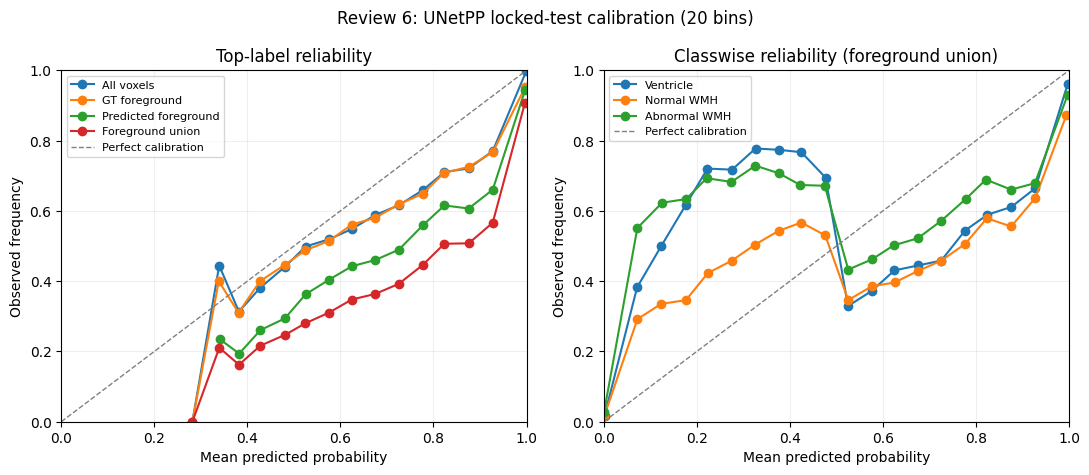

DOWNLOAD: /kaggle/working/Review6_ECE_UNetPP.zip
No temperature scaling, model selection, or retraining was performed.


In [10]:
all_hists=new_hists()
patient_rows=[]
for i,pid in enumerate(locked_test_ids,1):
    result=patient_calibration(pid,all_hists)
    patient_rows.append({'patient_id':pid,'model':MODEL_KEY,**result})
    print(f'{i:02d}/20 patient {pid}: foreground ECE {result["toplabel_gt_foreground"]:.5f}')
    gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()

patient_df=pd.DataFrame(patient_rows)
patient_df.to_csv(TABLE_DIR/'Review6_patientwise_ECE.csv',index=False)
summary=pd.DataFrame([{'model':MODEL_KEY,'metric':key,'voxel_count':int(h.n.sum()),'ece':h.ece()}
                      for key,h in all_hists.items()])
summary.to_csv(TABLE_DIR/'Review6_global_ECE.csv',index=False)
for key,h in all_hists.items():
    h.table().to_csv(TABLE_DIR/f'Review6_reliability_bins_{key}.csv',index=False)
display(summary)

# Reliability curves — top-label groups and class-wise one-vs-rest on foreground union.
fig,axes=plt.subplots(1,2,figsize=(11,4.8))
for key,label in [('toplabel_all','All voxels'),('toplabel_gt_foreground','GT foreground'),
                  ('toplabel_pred_foreground','Predicted foreground'),('toplabel_foreground_union','Foreground union')]:
    tab=all_hists[key].table();good=tab['count']>0
    axes[0].plot(tab.loc[good,'mean_confidence'],tab.loc[good,'empirical_accuracy'],marker='o',label=label)
for c,label in [(1,'Ventricle'),(2,'Normal WMH'),(3,'Abnormal WMH')]:
    tab=all_hists[f'ovr_{c}_foreground_union'].table();good=tab['count']>0
    axes[1].plot(tab.loc[good,'mean_confidence'],tab.loc[good,'empirical_accuracy'],marker='o',label=label)
for ax in axes:
    ax.plot([0,1],[0,1],ls='--',lw=1,color='gray',label='Perfect calibration')
    ax.set_xlim(0,1);ax.set_ylim(0,1);ax.set_xlabel('Mean predicted probability');ax.set_ylabel('Observed frequency')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
axes[0].set_title('Top-label reliability')
axes[1].set_title('Classwise reliability (foreground union)')
fig.suptitle(f'Review 6: {MODEL_KEY} locked-test calibration (20 bins)')
fig.tight_layout()
for ext in ['png','pdf']:
    fig.savefig(FIGURE_DIR/f'Review6_{MODEL_KEY}_reliability.{ext}',dpi=300,bbox_inches='tight')
plt.show()
import shutil
archive=shutil.make_archive(str(OUTPUT_DIR),'zip',root_dir=OUTPUT_DIR)
print('DOWNLOAD:',archive)
print('No temperature scaling, model selection, or retraining was performed.')